   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

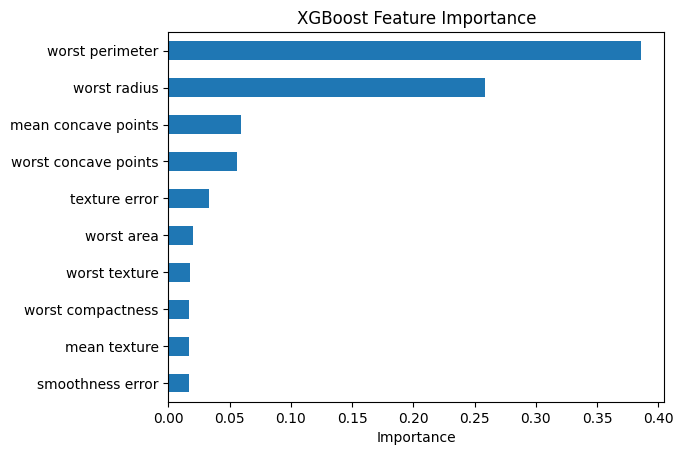

In [1]:
# ==========================================
# 1. Import Libraries
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

from xgboost import XGBClassifier


# ==========================================
# 2. Load Dataset
# ==========================================

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)


# ==========================================
# 3. Check Dataset
# ==========================================

print(X.head())
print(y.head())

print("Shape:", X.shape)
print("Target Classes:", y.unique())


# ==========================================
# 4. Train-Test Split
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# ==========================================
# 5. Create XGBoost Classifier
# ==========================================

model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",

    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,

    gamma=0,
    min_child_weight=1,

    reg_alpha=0,
    reg_lambda=1,

    random_state=42
)


# ==========================================
# 6. Train Model
# ==========================================

model.fit(X_train, y_train)


# ==========================================
# 7. Prediction
# ==========================================

y_pred = model.predict(X_test)


# ==========================================
# 8. Accuracy
# ==========================================

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)


# ==========================================
# 9. Confusion Matrix
# ==========================================

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)


# ==========================================
# 10. Classification Report
# ==========================================

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


# ==========================================
# 11. Prediction Probability
# ==========================================

y_probability = model.predict_proba(X_test)

print("\nFirst 5 Prediction Probabilities:")
print(y_probability[:5])


# ==========================================
# 12. Feature Importance
# ==========================================

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nTop Feature Importance:")
print(importance.head(10))


# ==========================================
# 13. Plot Feature Importance
# ==========================================

importance.head(10).sort_values().plot(kind="barh")

plt.title("XGBoost Feature Importance")
plt.xlabel("Importance")
plt.show()